Họ và tên: Vũ Trương Phi - MSSV: 6451071059


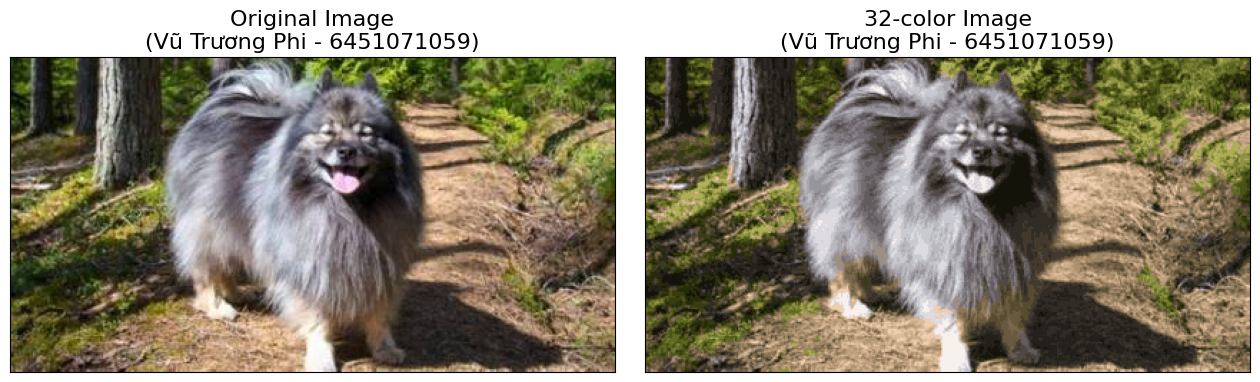

In [6]:
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans

# Khai báo thông tin sinh viên
ten = "Vũ Trương Phi"
mssv = "6451071059"
print(f"Họ và tên: {ten} - MSSV: {mssv}")

# 1. Đọc vào file ảnh cần giảm kích thước
image = Image.open("dog.png")

# 2. Chuyển ảnh đọc được thành mảng số và lấy thông tin chiều rộng, cao của ảnh
imarr = np.array(image)
rows = imarr.shape[0]
cols = imarr.shape[1]

# 3. Biến đổi các giá trị màu về [0...1] và chuyển dạng mảng thành 2 chiều
data = imarr / 255.0  # use 0...1 scale
data = data.reshape(rows * cols, 3)

# 4. Chạy thuật toán gom cụm với số màu là 32 và lấy ra mảng màu sau gom cụm
kmeans = KMeans(n_clusters=32, max_iter=300)
kmeans.fit(data)
new_colors = kmeans.cluster_centers_[kmeans.predict(data)]

# 5. Khôi phục dạng mảng từ 2 chiều thành 3 chiều như ban đầu
img_recolored = new_colors.reshape(imarr.shape)

# 6. Biểu diễn hình kết quả và so sánh với ảnh gốc ban đầu
fig, ax = plt.subplots(
    1, 2, figsize=(16, 6), subplot_kw=dict(xticks=[], yticks=[])
)
fig.subplots_adjust(wspace=0.05)
ax[0].imshow(image)
ax[0].set_title(f"Original Image\n({ten} - {mssv})", size=16)
ax[1].imshow(img_recolored)
ax[1].set_title(f"32-color Image\n({ten} - {mssv})", size=16)
plt.show()

# 7. Lưu hình kết quả xuống đĩa cứng
img_recolored = img_recolored * 255
new_img = Image.fromarray(img_recolored.astype(np.uint8))
new_img.save("compressed_img2.png")